Preprocessing section:

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
#reads in dataset, then chooses columns of interest
client_data = pd.read_csv("U_of_DE_Comp.csv")
client_data.head()

,Acct1,Acct2,Acct3,Acct4,Acct5,Acct6,Acct7,Acct8,Acct9,Acct10,...,line_12m,line_24m,PubRec1,Repo1,Score1,Score2,Util1,Util2,Util3,Util4
0,83,1,2,0,204,1,89,0,1,1,...,1000,1000,0,0,715,689,40,60,40,13
1,83,3,19,0,205,17,96,0,0,0,...,19500,19500,0,0,654,668,73,56,89,9
2,84,9,15,2,123,12,68,0,0,0,...,1000,1000,0,0,627,626,75,76,81,12
3,84,9,16,0,204,25,82,0,0,2,...,11000,11000,0,0,730,722,34,93,17,11
4,83,1,4,0,196,1,100,0,0,2,...,10000,10000,0,0,794,808,5,8,6,8


In [14]:
columns = ["Acct1", "Acct3", "Acct5", "Col1", "Del4", "Del6", "Acct7", "Del1", "bad_flg_90plus_24m", "consumer_bad_flg_90plus_24m"]
client_data = client_data[columns]
client_data.head()

,Acct1,Acct3,Acct5,Col1,Del4,Del6,Acct7,Del1,bad_flg_90plus_24m,consumer_bad_flg_90plus_24m
0,83,2,204,0,0,9996,89,1,0,0
1,83,19,205,0,0,17,96,1,0,0
2,84,15,123,0,0,47,68,6,0,0
3,84,16,204,0,0,58,82,6,0,0
4,83,4,196,0,0,9996,100,0,0,0


In [15]:
#describes dataset-- min, max, median, etc. 
client_data.describe()

,Acct1,Acct3,Acct5,Col1,Del4,Del6,Acct7,Del1,bad_flg_90plus_24m,consumer_bad_flg_90plus_24m
count,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000
mean,60.666363,8.034900,241.567463,0.491100,1.013220,6845.335520,92.401903,1.845000,0.063073,0.091187
std,26.599734,8.030728,589.592883,1.550031,7.612786,4634.334955,77.586507,3.598913,0.243095,0.287875
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,39.000000,3.000000,114.000000,0.000000,0.000000,51.000000,82.000000,0.000000,0.000000,0.000000
50%,73.000000,6.000000,194.000000,0.000000,0.000000,9996.000000,100.000000,0.000000,0.000000,0.000000
75%,84.000000,11.000000,289.000000,0.000000,0.000000,9996.000000,100.000000,2.000000,0.000000,0.000000
max,99.000000,99.000000,9999.000000,77.000000,99.000000,9999.000000,999.000000,99.000000,1.000000,1.000000


In [16]:
# the max value for acct1 is 99, which seems slightly inaccurate (see read me comments).
# replaces 99 values in acct1 with median value instead
acct1_clean_median = client_data.loc[client_data["Acct1"] != 99, "Acct1"].median()
print(acct1_clean_median)
client_data["Acct1"] = client_data["Acct1"].replace(99, acct1_clean_median)

73.0


In [17]:
# once again, max value for acct3 is 99-- seems off.
# replaces 99 values in acct3 with median value instead
acct3_clean_median = client_data.loc[client_data["Acct3"] != 99, "Acct3"].median()
print(acct3_clean_median)
client_data["Acct3"] = client_data["Acct3"].replace(99, acct3_clean_median)

6.0


In [18]:
# the max value for acct5 is 9999, which is not feasible.
# replaces 9999 values in acct5 with median value instead
acct5_clean_median = client_data.loc[client_data["Acct5"] != 9999, "Acct5"].median()
print(acct5_clean_median)
client_data["Acct5"] = client_data["Acct5"].replace(9999, acct5_clean_median)
# the max value for acc

193.0


In [19]:
# the max value for del6 is 9996, which is also not feasible.
# replaces 9996 values in del6 with median value instead
del6_clean_median = client_data.loc[client_data["Del6"] != 9996, "Del6"].median()
print(del6_clean_median)
client_data["Del6"] = client_data["Del6"].replace(9996, del6_clean_median)

23.0


In [20]:
Acct7_clean_median = client_data.loc[client_data["Acct7"] != 999, "Acct7"].median()
print(Acct7_clean_median)
client_data["Acct7"] = client_data["Acct7"].replace(999, Acct7_clean_median)

100.0


In [21]:
Del1_clean_median = client_data.loc[client_data["Del1"] != 99, "Del1"].median()
print(Del1_clean_median)
client_data["Del1"] = client_data["Del1"].replace(99, Del1_clean_median)

0.0


In [22]:
client_data.head()

,Acct1,Acct3,Acct5,Col1,Del4,Del6,Acct7,Del1,bad_flg_90plus_24m,consumer_bad_flg_90plus_24m
0,83,2,204,0,0,23,89,1,0,0
1,83,19,205,0,0,17,96,1,0,0
2,84,15,123,0,0,47,68,6,0,0
3,84,16,204,0,0,58,82,6,0,0
4,83,4,196,0,0,23,100,0,0,0


Next steps: build decision tree. find and evaluate feature importances. 
Machine learning section:

In [23]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [24]:
# defines independent and dependent variables
# splits the data in 30/70 split
# fits the decision tree using entropy as a criterion
# calculates predictions in classification report, and confusion matrix

X = client_data[["Acct1", "Acct3", "Acct5", "Col1", "Del4", "Del6"]]
y = client_data["bad_flg_90plus_24m"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size = 0.3,
    random_state = 42,
    stratify=y
)

tree = DecisionTreeClassifier(
    criterion="entropy",
    class_weight={0:1, 1:10},
    max_depth=3,
    min_samples_leaf=20,
    random_state=42
)

tree.fit(X_train, y_train)

y_pred = tree.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.96      0.86      0.91     84323
           1       0.20      0.53      0.30      5677

    accuracy                           0.84     90000
   macro avg       0.58      0.70      0.60     90000
weighted avg       0.92      0.84      0.87     90000

[[72562 11761]
 [ 2655  3022]]


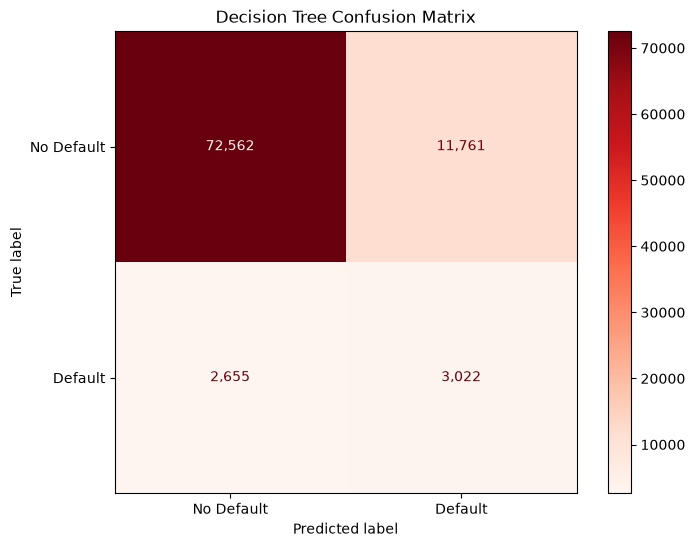

In [25]:
# better visual of confusion matrix
conf_matr = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=conf_matr,
    display_labels=["No Default", "Default"]
)

fig, ax = plt.subplots(figsize=(8,6))
display.plot(
    cmap="Reds",
    values_format=",",
    ax=ax
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

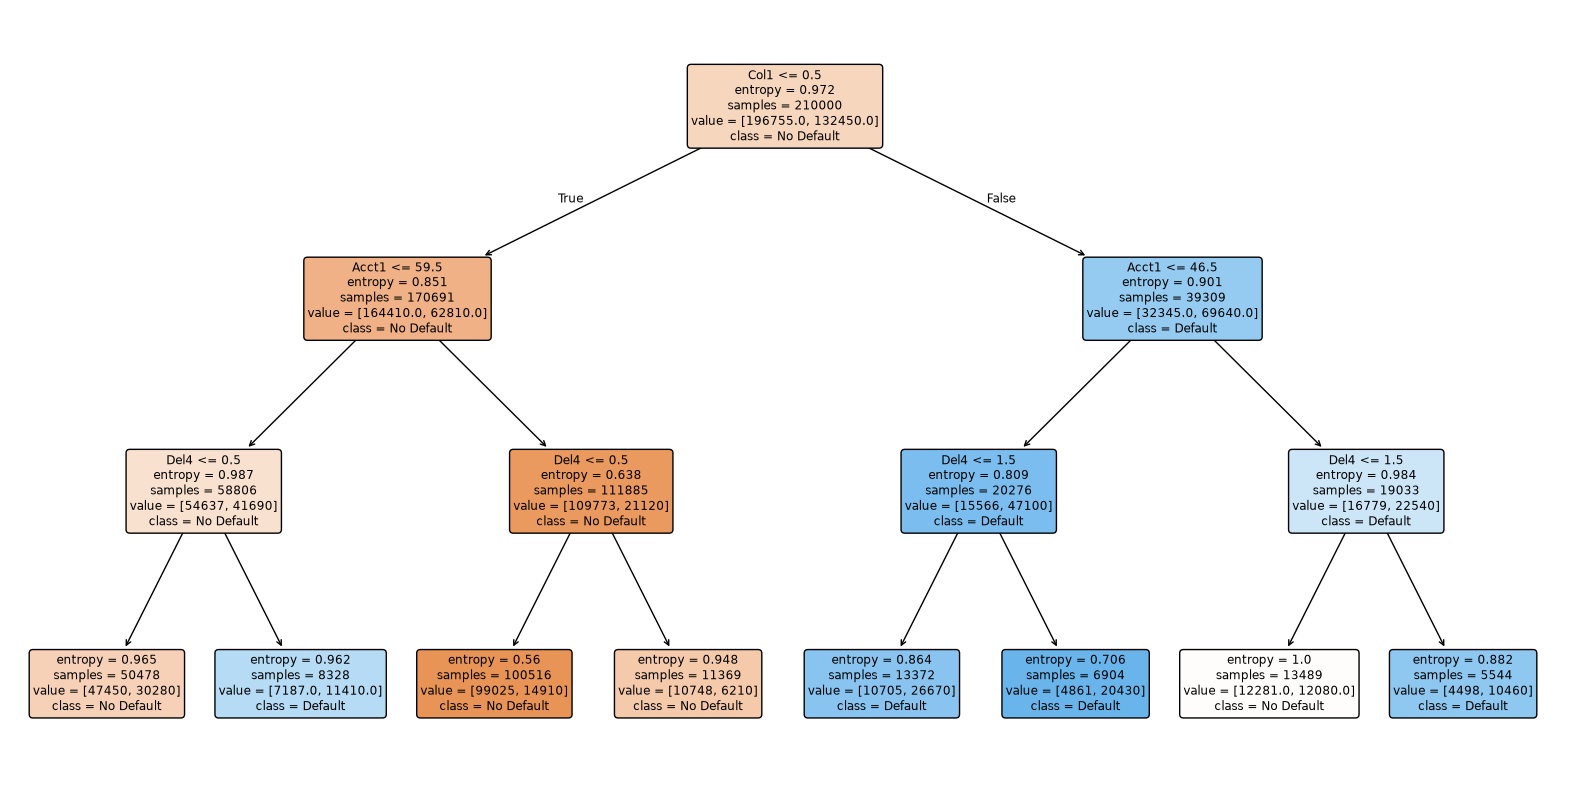

In [26]:
plt.figure(figsize=(20,10))

plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["No Default", "Default"],
    filled=True,
    rounded=True
)

plt.show()

In [27]:
# gives the relative importance for each predictor variable
# uses Gini importance
importance = pd.DataFrame({
    "Variable": X.columns,
    "Importance": tree.feature_importances_
})

print(
    importance.sort_values(
        "Importance",
        ascending=False
    )
)

  Variable  Importance
3     Col1    0.585205
0    Acct1    0.289485
4     Del4    0.125311
1    Acct3    0.000000
2    Acct5    0.000000
5     Del6    0.000000


In [28]:
# proportion of default/not default observations
client_data["bad_flg_90plus_24m"].value_counts(normalize=True)

bad_flg_90plus_24m
0    0.936927
1    0.063073
Name: proportion, dtype: float64

In [29]:
# random predictions, used as baseline
p = y_train.mean()  

np.random.seed(42)

y_random = np.random.choice(
    [0, 1],
    size=len(y_test),
    p=[1-p, p]
)

print(classification_report(y_test, y_random))

              precision    recall  f1-score   support

           0       0.94      0.94      0.94     84323
           1       0.07      0.06      0.07      5677

    accuracy                           0.88     90000
   macro avg       0.50      0.50      0.50     90000
weighted avg       0.88      0.88      0.88     90000



In [30]:
# improve f1_score. try random forest?
from sklearn.ensemble import RandomForestClassifier
tree = RandomForestClassifier(
    max_depth=10,
    max_samples=0.2,
    n_estimators=100,
)

tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)
print(classification_report(y_test, y_pred))

# well that actually made things worse.

              precision    recall  f1-score   support

           0       0.94      1.00      0.97     84323
           1       0.50      0.00      0.00      5677

    accuracy                           0.94     90000
   macro avg       0.72      0.50      0.48     90000
weighted avg       0.91      0.94      0.91     90000



In [31]:
# maybe if we try using consumer_bad_flg variable as dependent instead?
# finds proportion of 0 and 1 values for this var
client_data["consumer_bad_flg_90plus_24m"].value_counts(normalize=True)

consumer_bad_flg_90plus_24m
0    0.908813
1    0.091187
Name: proportion, dtype: float64

In [32]:
# we have 9% default cases now, which is a little better than regular bad_flg
# tries decision tree using consumer as y 

X = client_data[["Acct1", "Acct3", "Acct5", "Col1", "Del4", "Del6"]]
y = client_data["consumer_bad_flg_90plus_24m"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size = 0.3,
    random_state = 42,
    stratify=y
)

tree = DecisionTreeClassifier(
    criterion="entropy",
    class_weight={0: 1, 1: 5},
    max_depth=5,
    min_samples_leaf=20,
    random_state=42
)

tree.fit(X_train, y_train)

y_pred = tree.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

# still a lot of false negatives. f1 score for default cases 0.37
# maybe we just need more default cases?

              precision    recall  f1-score   support

           0       0.95      0.86      0.90     81793
           1       0.28      0.54      0.37      8207

    accuracy                           0.83     90000
   macro avg       0.61      0.70      0.64     90000
weighted avg       0.89      0.83      0.85     90000

[[70404 11389]
 [ 3794  4413]]


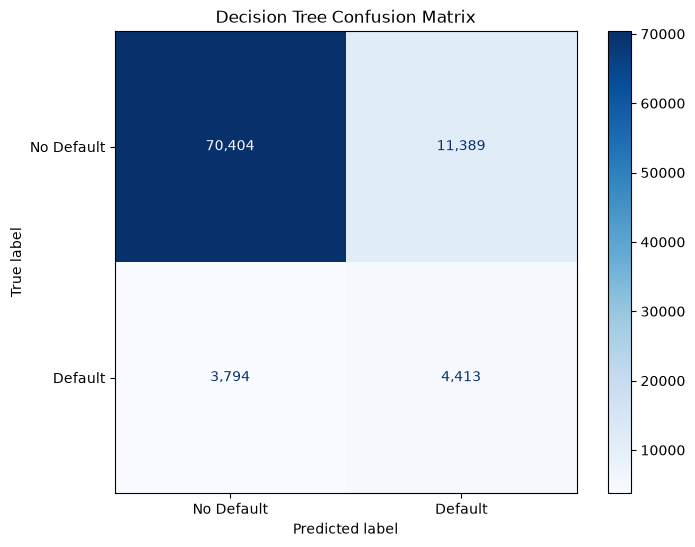

In [33]:
conf_matr = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=conf_matr,
    display_labels=["No Default", "Default"]
)

fig, ax = plt.subplots(figsize=(8,6))
display.plot(
    cmap="Blues",
    values_format=",",
    ax=ax
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

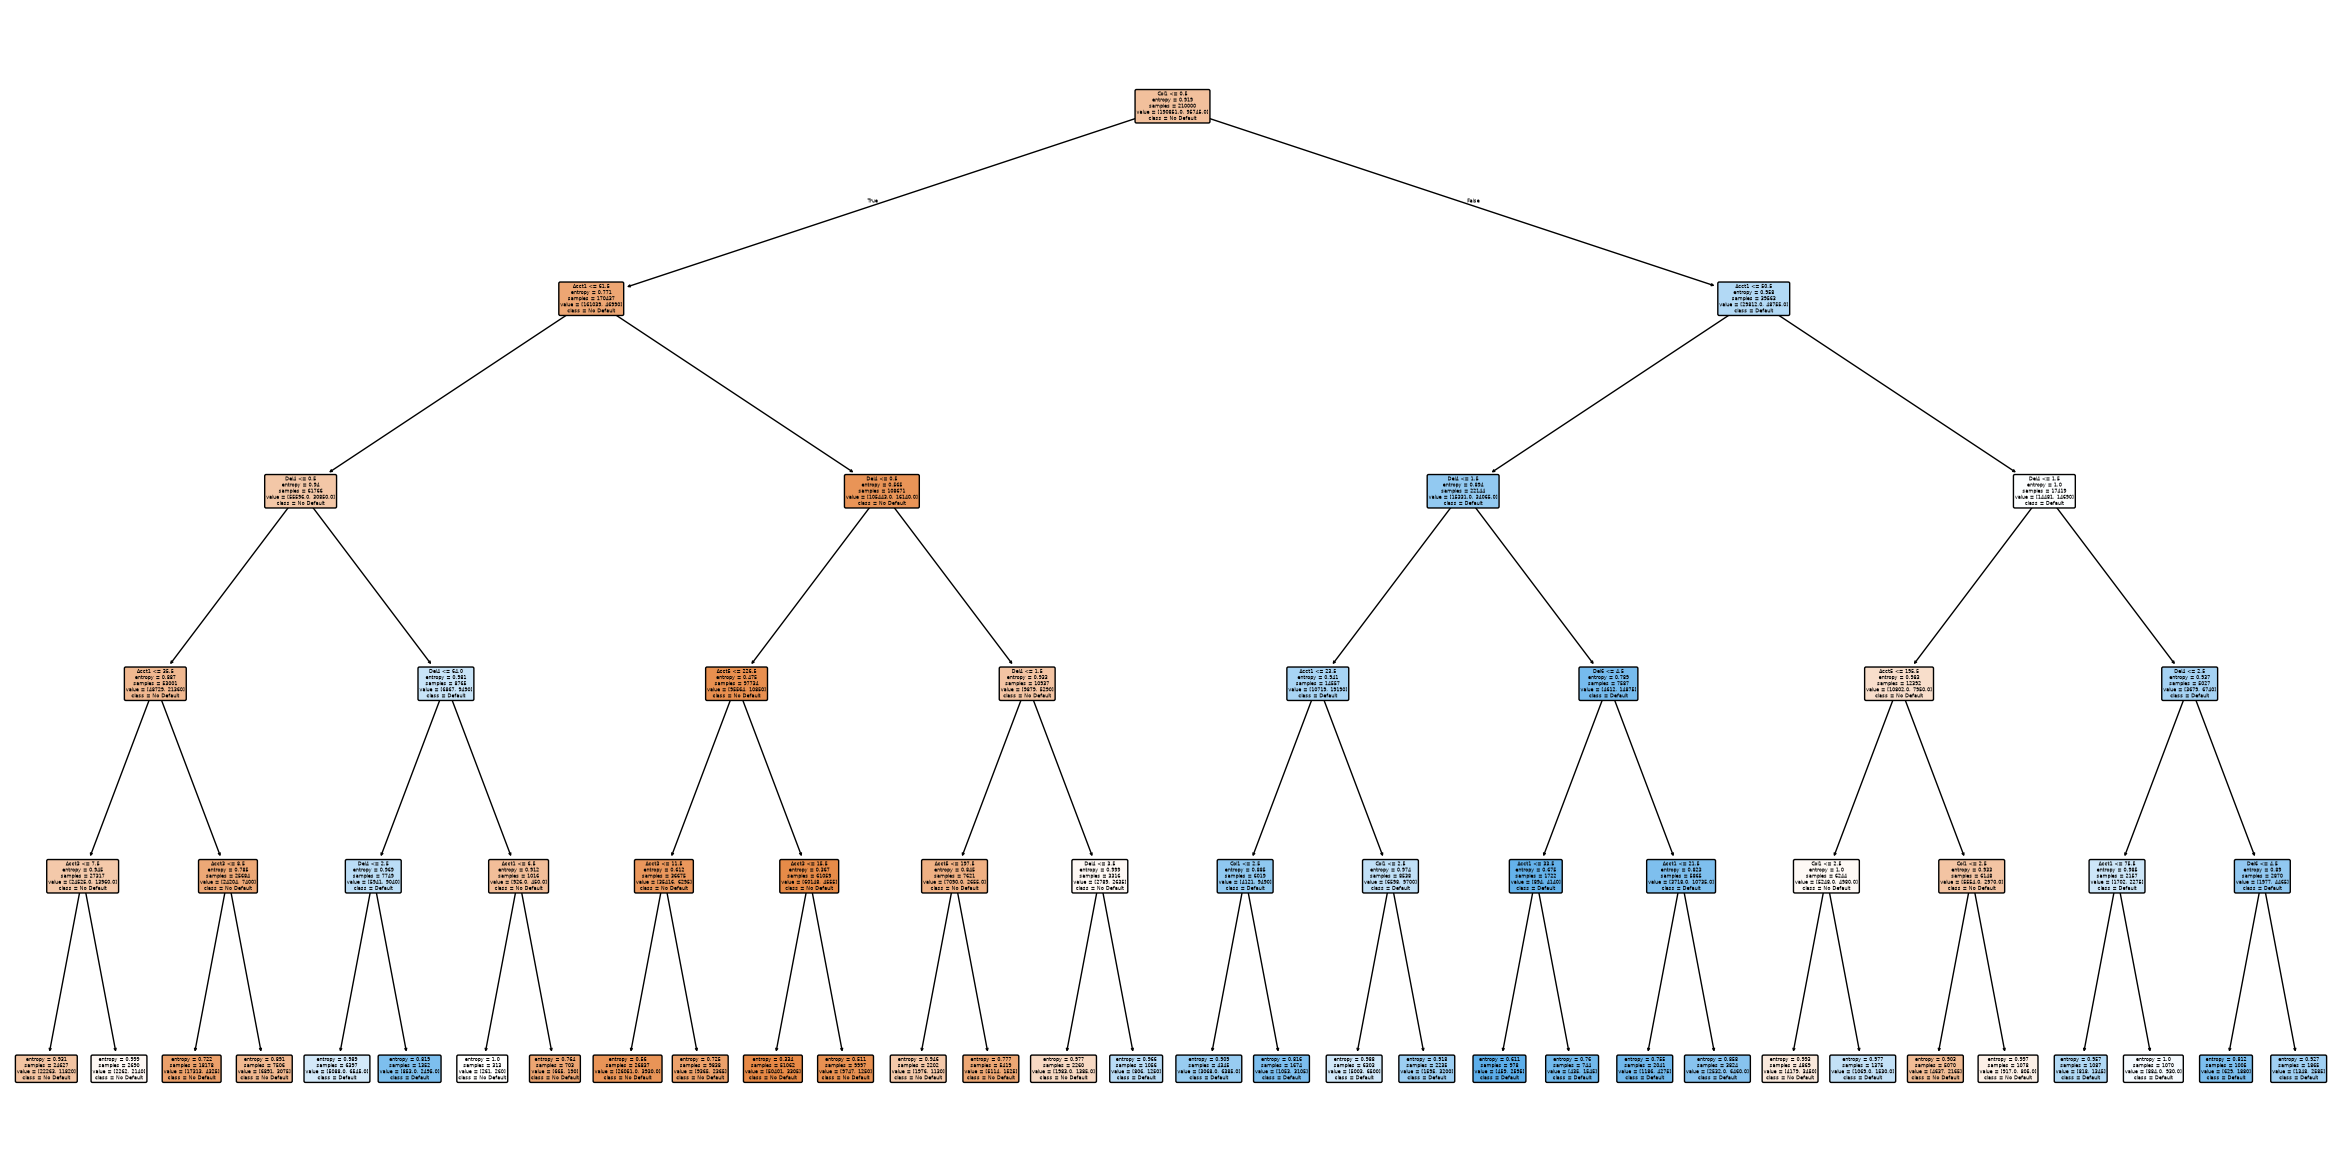

In [34]:
plt.figure(figsize=(30,15))

plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["No Default", "Default"],
    filled=True,
    rounded=True
)

plt.show()

In [35]:
# thoughts: a lot of false negatives.
# there may be better variables we can use to improve.
# look back at dataset again!

In [ ]:
# adds in Acct7 and Del1 variables

X = client_data[["Acct1", "Acct7", "Del4"]]
y = client_data["consumer_bad_flg_90plus_24m"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size = 0.3,
    random_state = 42,
    stratify=y
)

tree = DecisionTreeClassifier(
    criterion="entropy",
    class_weight={0:1, 1:10},
    max_depth=3,
    min_samples_leaf=20,
    random_state=42
)

tree.fit(X_train, y_train)

y_pred = tree.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.62      0.75     81793
           1       0.18      0.82      0.29      8207

    accuracy                           0.63     90000
   macro avg       0.57      0.72      0.52     90000
weighted avg       0.90      0.63      0.71     90000

[[50324 31469]
 [ 1470  6737]]


In [38]:
importance = pd.DataFrame({
    "Variable": X.columns,
    "Importance": tree.feature_importances_
})

print(
    importance.sort_values(
        "Importance",
        ascending=False
    )
)

  Variable  Importance
3    Acct7    0.788282
0    Acct1    0.194522
6     Del4    0.017196
1    Acct3    0.000000
2    Acct5    0.000000
4     Col1    0.000000
5     Del1    0.000000
7     Del6    0.000000
